## Individual trait shifts in each biome

Set path to include RStudio packages

In [2]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [3]:
# read /net/home/swolf/Func_Neo_Phytes/Data/tde202616123616.txt, skip first 3 lines, tab delimited
data <- read.table("/net/home/swolf/Func_Neo_Phytes/Data/tde202616123616.txt", skip = 3, header = TRUE, sep = "\t")

In [4]:
# Define the trait data
trait_ids <- c(4, 6, 13, 14, 15, 21, 26, 27, 46, 47, 50, 55, 78, 95, 138, 144, 145, 146, 163, 169, 
               223, 224, 237, 281, 282, 289, 297, 351, 614, 1080, 3086, 3106, 3107, 3108, 3109, 
               3110, 3111, 3112, 3113, 3114, 3115, 3116, 3117, 3120)

In [5]:
filtered_data <- data[data$TraitID %in% trait_ids, ]

In [6]:
# sort data by ObsNum, inverted
filtered_data <- filtered_data[order(-filtered_data$ObsNum), ]
filtered_data


,TraitID,Trait,ObsNum,ObsGRNum,AccSpecNum,X
,<int>,<chr>,<int>,<int>,<int>,<lgl>
1724,3106,Plant height vegetative,368479,268607,35466,NA
2064,26,Seed dry mass,317501,27134,43227,NA
1031,47,"Leaf dry mass per leaf fresh mass (leaf dry matter content, LDMC)",293469,277713,9688,NA
944,3117,"Leaf area per leaf dry mass (specific leaf area, SLA or 1/LMA): undefined if petiole is in- or exclu",249181,206176,16599,NA
2315,21,Stem diameter,215415,199436,8426,NA
1024,55,Leaf dry mass (single leaf),177383,151623,8696,NA
1143,14,Leaf nitrogen (N) content per leaf dry mass,165142,142471,13621,NA
1273,46,Leaf thickness,126654,116389,7773,NA
1319,3120,Leaf water content per leaf dry mass (not saturated),114633,114633,3608,NA


## Load Data

In [7]:

# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")


Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


In [8]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [9]:
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group.csv")
head(combined_data)

h3_res3,group,PC1,PC2,PC3,PC4,PC5,count,count_sp,mean_perc_na,⋯,X.X223,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,all,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,5.68,⋯,33.517,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000
83001afffffffff,native,-10.340785,1.3463123,-1.7276493,-1.0482630,-2.1657556,10,4,55.68,⋯,33.517,-0.016,3.884,-0.020,-0.698,85.452,2.183,3.140,-0.547,0.3330000
83001cfffffffff,all,-9.994814,-0.2430451,0.2367820,-2.9060144,-1.0022472,1,1,16.22,⋯,32.155,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3272027
83001cfffffffff,native,-10.002619,-0.3291607,0.3134314,-2.9203937,-0.9736157,1,1,116.22,⋯,32.155,-0.119,3.810,0.001,-0.744,92.099,2.545,3.121,-0.563,0.3360682
83001efffffffff,all,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,3.38,⋯,32.650,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000
83001efffffffff,native,-10.704678,-0.8306347,-0.9563224,0.2603966,-1.3077282,4,3,3.38,⋯,32.650,0.122,4.005,0.003,-0.699,88.269,2.311,3.671,-1.933,0.4090000


In [39]:
# Trait names

# Define the trait data
trait_ids <- c(4, 6, 13, 14, 15, 21, 26, 27, 46, 47, 50, 55, 78, 95, 138, 144, 145, 146, 163, 169, 
               223, 224, 237, 281, 282, 289, 297, 351, 614, 1080, 3086, 3106, 3107, 3108, 3109, 
               3110, 3111, 3112, 3113, 3114, 3115, 3116, 3117, 3120)

trait_names <- c(
  "Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density", "Root rooting depth", 
  "Leaf carbon (C) content per leaf dry mass", "Leaf nitrogen (N) content per leaf dry mass", 
  "Leaf phosphorus (P) content per leaf dry mass", "Stem diameter", "Seed dry mass", "Seed length", 
  "Leaf thickness", "Leaf dry mass per leaf fresh mass (leaf dry matter content, LDMC)", 
  "Leaf nitrogen (N) content per leaf area", "Leaf dry mass (single leaf)", 
  "Leaf nitrogen (N) isotope signature (delta 15N)", "Seed germination rate (germination efficiency)", 
  "Seed number per reproduction unit", "Leaf length", "Leaf width", "Leaf carbon/nitrogen (C/N) ratio", 
  "Leaf fresh mass", "Stem conduit density (vessels and tracheids)", "Species genotype: chromosome number", 
  "Species genotype: chromosome cDNA content", "Dispersal unit length", "Stem conduit diameter (vessels, tracheids)", 
  "Wood vessel element length; stem conduit (vessel and tracheids) element length", "Wood fiber lengths", 
  "Wood rays per millimetre (wood ray density)", "Seed number per dispersal unit", 
  "Fine root length per fine root dry mass (specific fine root length, SRL)", 
  "Root length per root dry mass (specific root length, SRL)", 
  "Leaf area per leaf dry mass (SLA or 1/LMA) petiole, rhachis and midrib excluded", "Plant height vegetative", 
  "Plant height generative", "Leaf area (in case of compound leaves: leaf, petiole excluded)", 
  "Leaf area (in case of compound leaves: leaflet, petiole excluded)", 
  "Leaf area (in case of compound leaves: leaf, petiole included)", 
  "Leaf area (in case of compound leaves: leaflet, petiole included)", 
  "Leaf area (in case of compound leaves: leaf, undefined if petiole in- or excluded)", 
  "Leaf area (in case of compound leaves: leaflet, undefined if petiole is in- or excluded)", 
  "Leaf area (in case of compound leaves undefined if leaf or leaflet, if petiole is in- or excluded)", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): petiole excluded", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): petiole included", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): undefined if petiole is in- or excluded", 
  "Leaf water content per leaf dry mass (not saturated)"
)


short_names <- c(
  "SSD", 
  "Rooting depth", 
  "Leaf C", 
  "Leaf N", 
  "Leaf P", 
  "Stem diameter", 
  "Seed dry mass", 
  "Seed length", 
  "Leaf thickness", 
  "LDMC", 
  "Leaf N per area", 
  "Leaf dry mass", 
  "Leaf delta 15N", 
  "Germination efficiency", 
  "Seed number/rep. unit", 
  "Leaf length", 
  "Leaf width", 
  "Leaf C/N ratio", 
  "Leaf fresh mass", 
  "Stem conduit density", 
  "Chromosome number", 
  "Chromosome cDNA content", 
  "Dispersal unit length", 
  "Stem conduit diameter", 
  "Wood vessel element length", 
  "Wood fiber lengths", 
  "Wood ray density", 
  "Seed number/disp. unit", 
  "Specific fine root length", 
  "Specific root length", 
  "SLA midrib excl.", 
  "Plant height veg.", 
  "Plant height gen.", 
  "Leaf area 3108 ", 
  "Leaf area 3109", 
  "Leaf area 3110", 
  "Leaf area 3111", 
  "Leaf area 3112", 
  "Leaf area 3113", 
  "Leaf area 3114", 
  "SLA petiole excl.", 
  "SLA petiole incl.", 
  "SLA petiole in- or excluded", 
  "Leaf water content not saturated"
)



sPlotOpen_name <- c(
  "SSD",          # SSD
  "",                      # Rooting depth
  "Leaf.C",  # Leaf C
  "Leaf.N.per.mass",             # Leaf N
  "Leaf.P",             # Leaf P
  "",                      # Stem diameter
  "Seed.mass",          # Seed dry mass
  "Seed.length",       # Seed length
  "",                      # Leaf thickness
  "LDMC",              # LDMC
  "Leaf.N.per.area",      # Leaf N per area
  "",                      # Leaf dry mass
  "Leaf.delta15N",    # Leaf delta 15N
  "",                      # Germination efficiency
  "Seeds.per.rep..unit", # Seed number/rep. unit
  "",                      # Leaf length
  "",                      # Leaf width
  "",       # Leaf C/N ratio
  "Leaf.fresh.mass",     # Leaf fresh mass
  "Stem.conduit.density",    # Stem conduit density
  "",                      # Chromosome number
  "",                      # Chromosome cDNA content
  "Dispersal.unit.length",    # Dispersal unit length
  "",                      # Stem conduit diameter
  "Conduit.element.length",# Wood vessel element length
  "",                      # Wood fiber lengths
  "",                      # Wood ray density
  "",                      # Seed number/disp. unit
  "",                      # Specific fine root length
  "",                      # Specific root length
  "",                      # SLA midrib excl.
  "Plant.Height",       # Plant height veg.
  "",                      # Plant height gen.
  "",                       # Leaf area 3108
  "",                      # Leaf area 3109
  "",                      # Leaf area 3110
  "",                      # Leaf area 3111
  "",                      # Leaf area 3112
  "",                      # Leaf area 3113
  "Leaf.Area",          # Leaf area 3114
  "",                      # SLA petiole excl.
  "",               # SLA petiole incl.
  "SLA",                      # SLA petiole in- or excluded
  ""                       # Leaf water content not saturated
)


unit_names <- c("g/cm3", "m", "mg/g", "mg/g", "mg/g", "m", "mg", "mm", "mm", "g/g", "g m-2", "mg", "per mill", 
                "%", "number", "mm", "cm", "g g-1", "g", "mm-2", "n", "pg", "mm", "micro m", "micro m", 
                "micro m", "1/mm", "number", "cm/g", "cm/g", "mm2/mg", "m", "m", "mm2", "mm2", "mm2", 
                "mm2", "mm2", "mm2", "mm2", "mm2/mg", "mm2/mg", "mm2/mg", "g(W)/g(DM)")

# add "X.X" prefix and "." suffix to TraitID
trait_ids_try6 <- paste0("X.X", trait_ids)

# Create the dataframe
traits <- data.frame(TraitID = trait_ids, TraitID_TRY6 = trait_ids_try6, TraitName = trait_names, ShortName = short_names, sPlotOpenName=sPlotOpen_name, UnitName = unit_names)

# View the dataframe
traits


TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6,Root rooting depth,Rooting depth,,m
13,X.X13,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21,Stem diameter,Stem diameter,,m
26,X.X26,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27,Seed length,Seed length,Seed.length,mm
46,X.X46,Leaf thickness,Leaf thickness,,mm


In [11]:
write.csv(traits, file="~/Func_Neo_Phytes/Data/trait_info.csv", row.names=FALSE)

In [12]:
traits

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m
26,X.X26.,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27.,Seed length,Seed length,Seed.length,mm
46,X.X46.,Leaf thickness,Leaf thickness,,mm


In [40]:
leaf_traits <- traits[startsWith(traits$ShortName, "Leaf area"), ]
leaf_traits_ids <- leaf_traits$TraitID_TRY6 
print(leaf_traits_ids)

[1] "X.X3108" "X.X3109" "X.X3110" "X.X3111" "X.X3112" "X.X3113" "X.X3114"


In [41]:
valid_leaf_trait_ids <- leaf_traits_ids[leaf_traits_ids %in% colnames(combined_data)]
valid_leaf_trait_ids

[1] "X.X3112" "X.X3113" "X.X3114"

In [42]:
sla_traits <- traits[startsWith(traits$ShortName, "SLA"), ]
sla_traits_ids <- sla_traits$TraitID_TRY6 
print(sla_traits_ids)

[1] "X.X3086" "X.X3115" "X.X3116" "X.X3117"


In [43]:
valid_sla_trait_ids <- sla_traits_ids[sla_traits_ids %in% colnames(combined_data)]
valid_sla_trait_ids

[1] "X.X3117"

In [44]:
# print colnames of combined_data that start with "X.X" and end with "."
dim(traits)
length(colnames(combined_data)[startsWith(colnames(combined_data), "X.X") & endsWith(colnames(combined_data), ".")])

[1] 44  6

[1] 0

In [23]:
combined_data <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_region_log10_notrim_misstree.csv")

## Significance Test for Trait shifts

In [24]:
trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]
#trait_columns <- c(trait_columns, "PC1", "PC2")

unpaired_wilcoxon_results <- combined_data %>%
    group_by(region) %>%
    summarise(
        across(
            all_of(trait_columns),
            ~ {
                group_all <- .x[group == "all"]
                group_native <- .x[group == "native"]
                if (length(na.omit(group_all)) > 1 && length(na.omit(group_native)) > 1) {
                    wilcox.test(group_all, group_native, paired = FALSE)$p.value
                } else {
                    NA  # Return NA if there are not enough observations
                }
            },
            .names = "wilcox_p_value_{col}"
        )
    )

Warning message:
“There were 697 warnings in `summarise()`.
The first warning was:
ℹ In argument: `across(...)`.
ℹ In group 2: `region = "10_AA"`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with ties
ℹ Run `dplyr::last_dplyr_warnings()` to see the 696 remaining warnings.”


In [25]:
# new df with adjusted p-values from unpaired_wilcoxon_results as * ** and *** and ns
significance_levels <- unpaired_wilcoxon_results %>%
    mutate(across(
        starts_with("wilcox_p_value_"),
        ~ p.adjust(.x, method = "BH"),
        .names = "adjusted_{col}"
    )) %>%
    mutate(across(
        starts_with("adjusted_wilcox_p_value_"),
        ~ case_when(
            .x <= 0.001 ~ "***",
            .x <= 0.01 ~ "**",
            .x <= 0.05 ~ "*",
            TRUE ~ ""
        ),
        .names = "sig_{col}"
    )) %>%
    dplyr::select(region, starts_with("sig_"))

In [26]:
# remove from significance_levels columns names the pattern "sig_adjusted_wilcox_p_value_" 
significance_levels <- significance_levels %>%
    rename_with(~ gsub("sig_adjusted_wilcox_p_value_", "", .), starts_with("sig_adjusted_wilcox_p_value_"))
    


In [27]:
significance_levels <- as.data.frame(significance_levels)
significance_levels

region,X.X3117,X.X14,X.X50,X.X146,X.X3120,X.X224,X.X297,X.X21,X.X13,⋯,X.X223,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
,,*,,*,,,,,,⋯,,,,,,,,,,
10_AA,,,,,,,,,,⋯,,,,,,,,,,
10_AT,*,***,,,,,,,,⋯,,,,,,,,,,
10_IM,,,,,,,,,,⋯,,,,,,,,,,
10_NT,,,,,,,,,,⋯,,,,,,,,,,
10_PA,,,,,,,,,,⋯,,,,,,,,,,
11_AA,,,,,,,,,,⋯,,,,,,,,,,
11_NA,,,,,,,,,,⋯,,,,,,,,,,
11_PA,,,,,,,,,,⋯,,,,,,,,,,


## Effect Sizes

In [29]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_results <- list()

# Get all trait columns that start with "X"
trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]

# Loop over all unique regions in combined_data
for (current_region in unique(combined_data$region)) {
    # Filter data for the current region
    filtered_data <- combined_data %>%
        filter(region == current_region & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Initialize a list to store Cliff's Delta for each trait
    region_results <- list()
    
    # Loop over all trait columns
    for (trait in trait_columns) {
        # Calculate Cliff's Delta for the current trait
        cliffs_delta <- tryCatch(
            {
                effsize::cliff.delta(
                    filtered_data[[trait]][filtered_data$group == "all"],
                    filtered_data[[trait]][filtered_data$group == "native"]
                )$estimate
            },
            error = function(e) NA
        )
        
        # Store the result
        region_results[[trait]] <- cliffs_delta
    }
    
    # Combine results for the current region into a data frame
    cliffs_delta_results[[current_region]] <- data.frame(
        region = current_region,
        t(region_results)  # Transpose the list to create columns for each trait
    )
}

# Combine all results into a single data frame
cliffs_delta_results_df <- bind_rows(cliffs_delta_results)
# Rename columns to include "effect_" prefix, except for the "region" column
colnames(cliffs_delta_results_df)[-1] <- paste0("effect_", colnames(cliffs_delta_results_df)[-1])

head(cliffs_delta_results_df)


Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence I

,region,effect_X.X3117,effect_X.X14,effect_X.X50,effect_X.X146,effect_X.X3120,effect_X.X224,effect_X.X297,effect_X.X21,effect_X.X13,⋯,effect_X.X223,effect_X.X237,effect_X.X614,effect_X.X351,effect_X.X6,effect_X.X95,effect_X.X138,effect_X.X1080,effect_X.X78,effect_X.X4
,<chr>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,⋯,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>
1,11_PA,0.0119233,0.02419728,-0.00119233,-0.0163279,0.0108993,0.006129978,-0.01304549,-0.005695128,-0.01162872,⋯,-0.008654912,0.005049867,0.004530853,-0.001557042,0.01123596,-0.003408661,0.01227398,0.0007013705,0.007616883,0.00162718
2,,0.1201271,0.1447073,0.0150804,-0.1277721,0.005935388,0.05064434,0.01075789,0.01119337,0.008483734,⋯,-0.09791778,-0.03361236,-0.004145094,-0.1322398,-0.04278963,0.03006403,0.01514492,-0.08383736,0.06617635,-0.05528943
3,11_NA,0.003946509,0.02171034,0.0002358833,-0.01451589,0.007330527,0.002930396,0.001905211,-0.01830817,-0.01061475,⋯,-0.008500871,-0.0003084628,-0.000753012,0.001242924,0.005289229,0.007022064,0.009117796,0.00823777,0.01471549,-0.005389026
4,6_PA,0.02319181,0.05717209,0.007775839,-0.04217137,0.03432225,-0.005544865,-0.03987526,-0.003020771,-0.03180359,⋯,-0.02026332,0.02232331,0.008527639,-0.008115099,0.024538,0.0199512,0.02397075,-0.009149163,0.02775689,-0.00604697
5,5_PA,0.03621338,0.1506316,0.04340231,-0.08882021,0.02452298,-0.05529428,0.01699812,-0.04158828,-0.04958345,⋯,-0.04958345,-0.01437786,0.0712846,0.01061543,0.02747917,0.02694168,0.04138672,0.02620263,0.1416958,0.006382693
6,4_PA,0.04630322,0.09787128,0.06582525,-0.01573785,0.02931876,-0.05673188,-0.05946778,0.05296865,0.01322368,⋯,-0.05957618,0.06758799,0.0263636,0.08423862,0.06841332,-0.01783935,0.01712981,-0.01126631,0.1454125,-0.01034244


In [30]:
# filter effect_sizes based on significance_levels that are "*", "**", or "***"
filtered_effect_sizes <- cliffs_delta_results_df %>%
    left_join(significance_levels, by = "region") %>%
    mutate(across(
        starts_with("effect_"),
        ~ {
            sig_col <- paste0(gsub("effect_", "", cur_column()))
            sig_values <- get(sig_col)
            ifelse(sig_values %in% c("*", "**", "***"), .x, NA  )
        }
    ))

# remove columns that start with "X"
filtered_effect_sizes <- filtered_effect_sizes %>%
    dplyr::select(region, starts_with("effect_"))

# remove "effect_" prefix from column names
colnames(filtered_effect_sizes)[-1] <- gsub("effect_", "", colnames(filtered_effect_sizes)[-1])


filtered_effect_sizes

region,X.X3117,X.X14,X.X50,X.X146,X.X3120,X.X224,X.X297,X.X21,X.X13,⋯,X.X223,X.X237,X.X614,X.X351,X.X6,X.X95,X.X138,X.X1080,X.X78,X.X4
<chr>,<list>,<list>,<list>,<list>,<list>,<list>,<lgl>,<list>,<list>,⋯,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>
11_PA,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
,NA,0.1447073,NA,-0.1277721,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
11_NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
6_PA,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
5_PA,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
4_PA,NA,0.09787128,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,0.08423862,NA,NA,NA,NA,0.1454125,NA
8_PA,NA,0.1075051,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
6_NA,NA,0.1309828,NA,-0.1124021,NA,NA,NA,-0.1391852,NA,⋯,NA,NA,NA,NA,NA,0.1382332,NA,NA,NA,NA
5_NA,NA,0.4033741,NA,-0.371749,0.2556171,NA,NA,-0.148892,-0.1646853,⋯,NA,NA,NA,-0.1745152,NA,0.2997076,NA,0.1756502,0.166609,-0.196849


## Plot Effect Sizes

In [46]:
library(tidyr)  # Load the tidyr package

df_long <- significance_levels %>%
    pivot_longer(
        cols = -region,
        names_to = "trait",
        values_to = "signif"
    ) %>%
    filter(signif != "" & !is.na(signif)) %>%   # keep only significant shifts
    mutate(weight = case_when(
        signif == "*" ~ 1,
        signif == "**" ~ 2,
        signif == "***" ~ 3
    ))


In [47]:
library(dplyr)
library(tidyr)

# convert all trait columns from list -> numeric
trait_cols <- grep("^X", names(filtered_effect_sizes), value = TRUE)

filtered_effect_sizes <- filtered_effect_sizes %>%
  mutate(across(all_of(trait_cols), ~ unlist(.)))


In [ ]:
library(dplyr)
library(tidyr)

df_long_eff <- filtered_effect_sizes %>%
  pivot_longer(
    cols = all_of(trait_cols),
    names_to = "trait",
    values_to = "effect_size"
  ) %>%
  filter(!is.na(effect_size))   # keep only significant shifts

head(df_long_eff)

region,trait,effect_size
<chr>,<chr>,<dbl>
,X.X14,0.14470734
,X.X146,-0.12777213
4_PA,X.X14,0.09787128
4_PA,X.X169,-0.09501343
4_PA,X.X281,0.09455642
4_PA,X.X282,-0.13500846


In [49]:
# merge df_long and df_long_eff by region and trait
df_long <- df_long %>%
    left_join(df_long_eff, by = c("region", "trait"))    
head(df_long)

region,trait,signif,weight,effect_size
<chr>,<chr>,<chr>,<dbl>,<dbl>
,X.X14,*,1,0.1447073
,X.X146,*,1,-0.1277721
10_AT,X.X3117,*,1,0.2598691
10_AT,X.X14,***,3,0.4225352
10_AT,X.X15,***,3,0.3828605
10_AT,X.X47,*,1,-0.2973616


In [50]:
head(traits)

,TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,4,X.X4,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
2,6,X.X6,Root rooting depth,Rooting depth,,m
3,13,X.X13,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
4,14,X.X14,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
5,15,X.X15,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
6,21,X.X21,Stem diameter,Stem diameter,,m


In [51]:
# replace trait name with corresponding "ShortName" from traits dataframe
df_long <- df_long %>% left_join(traits %>% dplyr::select(TraitID_TRY6, ShortName), by = c("trait" = "TraitID_TRY6")) %>%
  rename(trait_name = ShortName)

In [52]:
df_long

region,trait,signif,weight,effect_size,trait_name
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
,X.X14,*,1,0.1447073,Leaf N
,X.X146,*,1,-0.1277721,Leaf C/N ratio
10_AT,X.X3117,*,1,0.2598691,SLA petiole in- or excluded
10_AT,X.X14,***,3,0.4225352,Leaf N
10_AT,X.X15,***,3,0.3828605,Leaf P
10_AT,X.X47,*,1,-0.2973616,LDMC
10_NT,X.X15,*,1,0.2683824,Leaf P
12_AA,X.X3117,*,1,0.2108619,SLA petiole in- or excluded
12_AA,X.X3120,*,1,0.2469976,Leaf water content not saturated


In [53]:
# number of unique regions and traits with significant shifts
num_regions <- length(unique(df_long$region))
num_traits <- length(unique(df_long$trait))
num_regions 
num_traits


[1] 33

[1] 35

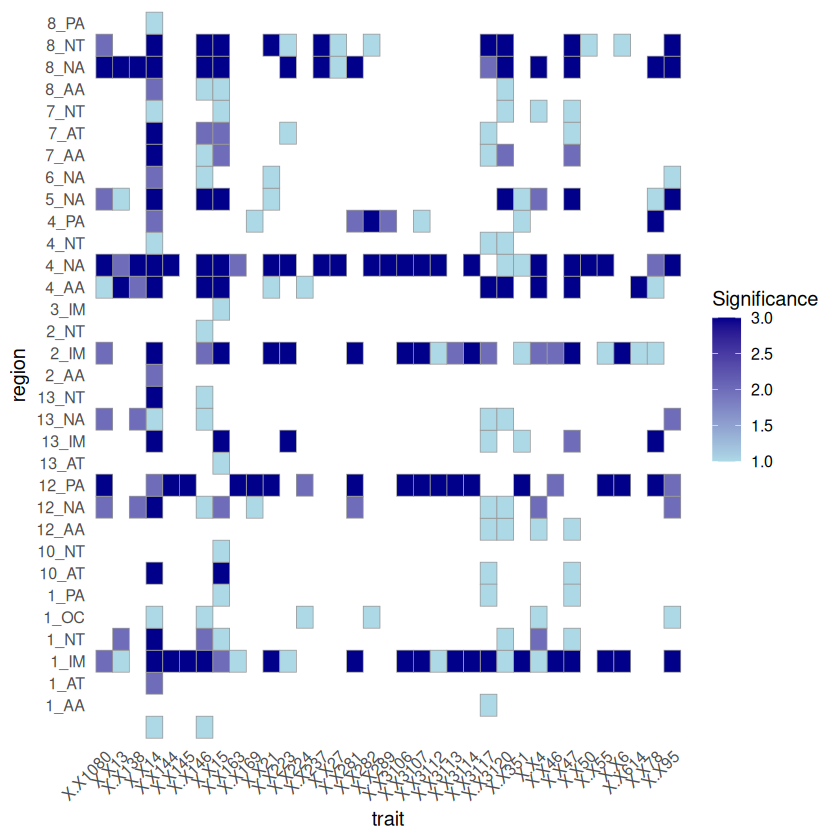

In [54]:
library(ggplot2)
library(dplyr)

df_plot <- df_long %>%
  mutate(signif_num = case_when(
    signif == "*" ~ 1,
    signif == "**" ~ 2,
    signif == "***" ~ 3
  ))

p <- ggplot(df_plot, aes(trait, region, fill = signif_num)) +
  geom_tile(color = "grey60") +
  scale_fill_gradient(
    name = "Significance", 
    low = "lightblue", 
    high = "darkblue"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    panel.grid.major = element_blank(),  # Remove default grid lines
    panel.grid.minor = element_blank()   # Remove minor grid lines
  )
  # Save the plot as a PNG file
  ggsave("~/Func_Neo_Phytes/Results/Figures/trait_significance_heatmap_log10_misstree.png", plot = p, width = 10, height = 9, dpi = 300)

print(p)

In [55]:
head(df_long)

region,trait,signif,weight,effect_size,trait_name
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
,X.X14,*,1,0.1447073,Leaf N
,X.X146,*,1,-0.1277721,Leaf C/N ratio
10_AT,X.X3117,*,1,0.2598691,SLA petiole in- or excluded
10_AT,X.X14,***,3,0.4225352,Leaf N
10_AT,X.X15,***,3,0.3828605,Leaf P
10_AT,X.X47,*,1,-0.2973616,LDMC


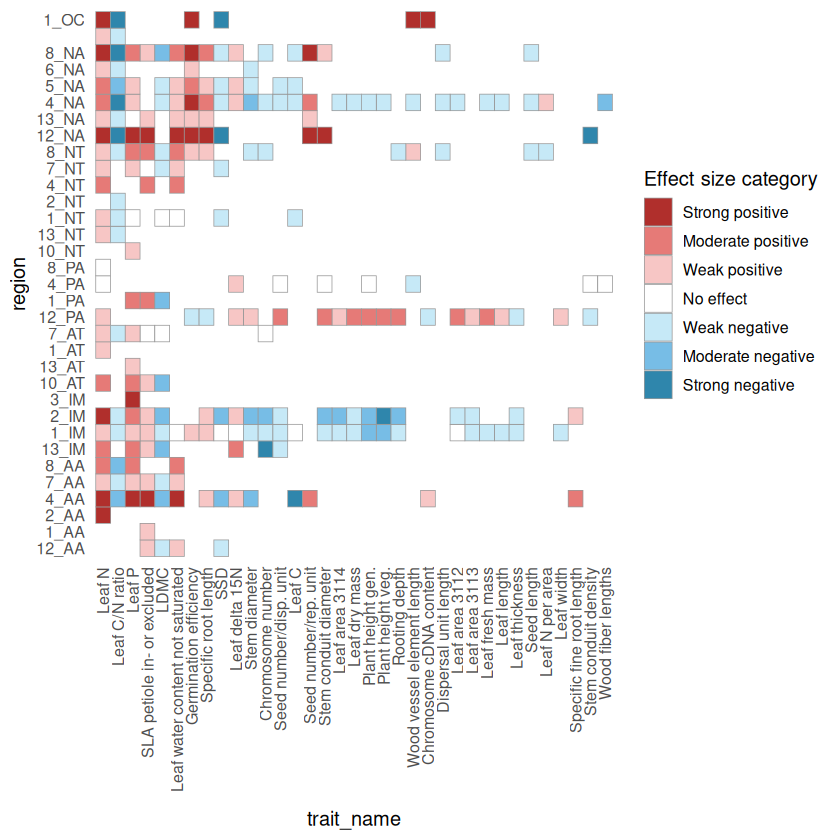

In [57]:

df_plot <- df_long %>%
  mutate(effect_size_category = case_when(
      effect_size >= 0.11 & effect_size < 0.28 ~ 1,
      effect_size >= 0.28 & effect_size < 0.43 ~ 2,
      effect_size >= 0.43 ~ 3,
      effect_size > -0.11 & effect_size < 0.11 ~ 0,
      effect_size <= -0.11 & effect_size > -0.28 ~ -1,
      effect_size <= -0.28 & effect_size > -0.43 ~ -2,  
      effect_size <= -0.43 ~ -3
    )) %>%
  group_by(trait_name) %>%
  mutate(non_zero_count = sum(effect_size_category != 0, na.rm = TRUE)) %>%
  ungroup() %>%
  mutate(trait_name = reorder(trait_name, -non_zero_count))  # Sort traits by non-zero count

library(stringr)  # optional, for str_extract

df_plot <- df_plot %>%
  mutate(region_order = factor(
    sub(".*_", "", region),
    c("AA", "IM", "AT", "PA", "NT", "NA"))) %>%  # Extract and order by specified levels
  mutate(region = factor(region, levels = unique(region[order(region_order)])))  # Reorder factor


p <- ggplot(df_plot, aes(trait_name, region, fill = factor(effect_size_category, levels = rev(c("-3", "-2", "-1", "0", "1", "2", "3"))))) +
  geom_tile(color = "grey60") +
  scale_fill_manual(
    name = "Effect size category",
    values = c(
      "-3" = "#2F86AC",
      "-2" = "#77bde6",
      "-1" = "#c6e9f7",
      "0" = "white",
      "1" = "#f7c6c5",
      "2" = "#e67a77",
      "3" = "#b02f2c"
    ),
    labels = c(
      "-3" = "Strong negative",
      "-2" = "Moderate negative",
      "-1" = "Weak negative",
      "0" = "No effect",
      "1" = "Weak positive",
      "2" = "Moderate positive",
      "3" = "Strong positive"
    )
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )

ggsave("~/Func_Neo_Phytes/Results/Figures/trait_effect_heatmap_log10_misstree.png", plot = p, width = 10, height = 10, dpi = 300)
print(p)
